# Pacbio processing

Use long read data to make barcode-substitution map used by 10x

Each pacbio read should cover the STING coding region, followed by a downstream region that contains:
- 21 bp fixed sequence
- 16 bp barcode - unique clonal identifier
- 4 bp spacer - usually CGCT but sometimes XXXX
- 16 digit TWIST barcode - indicates the position of the AA mutation in STING
- 1-bp spacer
- 22 bp 10x capture sequence (fixed)

This code reads through the reads, aligns to STING sequence, and matches the observed AA mutations in STING with the 16+4+16 bp barcode
to create a barcode-variant map, which is later used to assign variants in 10x cells


In [1]:
import csv
import multiprocessing
import os
import subprocess
import sys
import time
from importlib.metadata import version
from io import StringIO

import editdistance  # pip install editdistance
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from cigar import Cigar  # pip install Cigar
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle


In [2]:
print(f"Python: {sys.version.split()[0]}")

packages = [
    "editdistance",
    "matplotlib",
    "numpy",
    "pandas",
    "seaborn",
    "Cigar",
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.10.12
editdistance: 0.8.1
matplotlib: 3.8.3
numpy: 1.26.4
pandas: 2.2.1
seaborn: 0.13.2
Cigar: 0.1.3


__Minimap2 is needed, set path to minimap2 or else use next cell to download it__

In [3]:
minimap2_executable='/opt/minimap2-2.28_x64-linux/minimap2'

In [4]:
# Get minimap2 if needed
if minimap2_executable is None or not os.path.exists(minimap2_executable):
    !mkdir -p /opt
    !cd /opt && wget https://github.com/lh3/minimap2/releases/download/v2.28/minimap2-2.28_x64-linux.tar.bz2  && tar -jxvf minimap2-2.28_x64-linux.tar.bz2
    minimap2_executable='/opt/minimap2-2.28_x64-linux/minimap2'

In [5]:
!{minimap2_executable} --version

2.28-r1209


In [6]:
# Print working directory for reference

os.getcwd()

'/workdir/satseq/satseq_processing'

## Initial set-up

__Set input file name (.bam from pacbio)__

In [7]:
# bamfile
bamfile = '/workdir/satseq/pacbio_data/1_A01/hifi_reads/m84094_250121_165133_s1.hifi_reads.bam'

In [8]:
refseq_file='data/STING.fa'

__Set output directory__

In [9]:
# set directory for output files / plots
outdir='/workdir/satseq/pacbio_data/processed/1_A01'
!mkdir -p {outdir}

__Set sample name__

In [10]:
# set name of the sample to appear in plot titles
sample_name='4T1 pacbio'

# Replace spaces with underscore for ouptut filenames
sample_name_nospace=sample_name.replace(' ', '_')  

__Set 10x barcode__

In [11]:
# Set 10x barcode / capture sequence
bc10x='GCTTTAAGGCCGGTCCTAGCAA'

__Read in reference STING sequence and get coding start/end positions info__

In this notebook, there is only one reference sequence. But there could be multiple reference sequences in the fasta file, in which case it would align
long reads against all of them. This was originally intended to support some special STING variants (dUPR/dCTT) that have different lengths than WT sting,
but we found it was not necessary, the mapping worked OK for all variants using one single reference

In [12]:
with open(refseq_file, 'r') as f:
    tmpseq = f.readlines()
    f.close()
    refgene = {}
    for line in tmpseq:
        if line.startswith('>'):
            seqname = line[1:].strip()
            print(seqname)
            refgene[seqname]=''
        else:
            refgene[seqname] = refgene[seqname]+line.strip()
    print(refgene.keys())

STING
dict_keys(['STING'])


In [13]:
codon_table = {
    # 'M' - START, '_' - STOP
    "GCT": "A", "GCC": "A", "GCA": "A", "GCG": "A",
    "TGT": "C", "TGC": "C",
    "GAT": "D", "GAC": "D",
    "GAA": "E", "GAG": "E",
    "TTT": "F", "TTC": "F",
    "GGT": "G", "GGC": "G", "GGA": "G", "GGG": "G",
    "CAT": "H", "CAC": "H",
    "ATA": "I", "ATT": "I", "ATC": "I",
    "AAA": "K", "AAG": "K",
    "TTA": "L", "TTG": "L", "CTT": "L", "CTC": "L", "CTA": "L", "CTG": "L",
    "ATG": "M",
    "AAT": "N", "AAC": "N",
    "CCT": "P", "CCC": "P", "CCA": "P", "CCG": "P",
    "CAA": "Q", "CAG": "Q",
    "CGT": "R", "CGC": "R", "CGA": "R", "CGG": "R", "AGA": "R", "AGG": "R",
    "TCT": "S", "TCC": "S", "TCA": "S", "TCG": "S", "AGT": "S", "AGC": "S",
    "ACT": "T", "ACC": "T", "ACA": "T", "ACG": "T",
    "GTT": "V", "GTC": "V", "GTA": "V", "GTG": "V",
    "TGG": "W",
    "TAT": "Y", "TAC": "Y",
    "TAA": "_", "TAG": "_", "TGA": "_"
}


In [14]:
# find start position of STING in the reference sequence, and the end codon
genestart = {}
geneend = {}
refgene_aa = {}
for k,refseq in refgene.items():
    genestart[k] = refseq.find('ATGCCATACTCCAACCTGCATCCAGCCATCCCAC')
    aaseq=''
    for i in np.arange(genestart[k], len(refseq), 3):
        aa = codon_table[refseq[i:(i+3)]]
        aaseq += aa
        if aa == '_':
            geneend[k] = i
            break
    print(k, len(aaseq))
    refgene_aa[k] = aaseq

STING 379


In [15]:
genestart

{'STING': 465}

In [16]:
geneend

{'STING': 1599}

__Read in twist variants__

In [17]:
variants = pd.read_csv('data/twist_mSTING_full_feature_ref_v3.csv', index_col=0)
variants = variants.set_index('name', drop=True)

In [18]:
# This dataframe should have variant as the index, and the associated barcode as the 'sequence'. Other columns are not used here
variants

,read,pattern,sequence,feature_type
name,,,,
mSTING_WT,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CGAGGAATTAGCAACG,Custom
STOP,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GTAATGAATACCGAGG,Custom
V146L,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGGCGGCGAATATAGC,Custom
N153S,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CCTCGAGAACTTTCCT,Custom
V154M,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GGAATCAGACTGAAAC,Custom
...,...,...,...,...
R374X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GCTAACCAACTACCTC,Custom
T375X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGTAACATCCGTCGAA,Custom
D376X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GAGTTACTCATCGTCT,Custom


In [19]:
# check the barcode len, should be same for all sequences
{len(x) for x in variants['sequence']}

{16}

In [20]:
# assign a position, wt AA, and mutant AA to each variant. Most are indicated in variant name,
# but some special ones need values assigned. Use negative positions for non-positional variants

variants['pos'] = -1
variants['wt_aa'] = ''
variants['mut_aa'] = ''
for x in variants.index:
    wtaa=''
    mutaa=''
    pos=-100
    if x == 'STOP':
        pos = -2
    elif x == 'mSTING_WT':
        pos = 0
    elif x == 'dUPR':
        pos = -1
    elif x == 'dCTT':
        pos = -3
    elif x == 'RRDD':
        pos = -4
    elif x == 'RRAA':
        pos = -5
    elif x == '261X':
        pos = 261
        tmp = genestart['STING'] + 260*3
        wtaa=codon_table[refgene['STING'][tmp:(tmp+3)]]
        
    else:
        if x[len(x)-1] == 'X' or x=='V146L' or x == 'N153S' or x=='Y239S' or x == 'S365A' or x == 'V154M' or x=='S161A' or x=='I229A' or x=='N241A':
            tmp = int(x[1:(len(x)-1)])
            pos = tmp
            wtaa=x[0]
            mutaa=x[len(x)-1]
        else:
            print(f'Error {x}')
    variants.loc[x,'pos'] = pos
    variants.loc[x,'wt_aa'] = wtaa
    variants.loc[x,'mut_aa'] = mutaa

## preprocessing: convert input files to fastq.gz and do alignment with minimap

These steps may take up to an hour (esp alignment step)

In [21]:
bamfile

'/workdir/satseq/pacbio_data/1_A01/hifi_reads/m84094_250121_165133_s1.hifi_reads.bam'

In [22]:
outdir

'/workdir/satseq/pacbio_data/processed/1_A01'

In [23]:
# Use minimap2 to align long reads to each version of refseq
for ref in ['STING']:
    aligned_file =f'{outdir}/{ref}.bam'
    cmd=f'samtools bam2fq {bamfile} | {minimap2_executable} --eqx -ax map-hifi -t 10 {refseq_file} - | samtools view -b -o {aligned_file}'
    print(f'Calling: {cmd}')
    !{cmd}
print('Done')

Calling: samtools bam2fq /workdir/satseq/pacbio_data/1_A01/hifi_reads/m84094_250121_165133_s1.hifi_reads.bam | /opt/minimap2-2.28_x64-linux/minimap2 --eqx -ax map-hifi -t 10 data/STING.fa - | samtools view -b -o /workdir/satseq/pacbio_data/processed/1_A01/STING.bam
[M::mm_idx_gen::0.002*2.73] collected minimizers
[M::mm_idx_gen::0.004*5.66] sorted minimizers
[M::main::0.004*5.61] loaded/built the index for 1 target sequence(s)
[M::mm_mapopt_update::0.004*5.42] mid_occ = 50
[M::mm_idx_stat] kmer size: 19; skip: 19; is_hpc: 0; #seq: 1
[M::mm_idx_stat::0.004*5.28] distinct minimizers: 166 (100.00% are singletons); average occurrences: 1.000; average spacing: 10.777; total length: 1789
[M::worker_pipeline::15.533*1.76] mapped 171541 sequences
[M::worker_pipeline::25.481*3.19] mapped 185764 sequences
[M::worker_pipeline::43.072*6.09] mapped 273272 sequences
[M::worker_pipeline::49.458*5.74] mapped 275210 sequences
[M::worker_pipeline::64.350*6.68] mapped 275354 sequences
[M::worker_pipeline

## Parse alignment to get AA mutations and barcodes

In [24]:
def get_aa_from_codon(cod):
    if '-' in cod:
        return '-'
    if cod in codon_table:
        return codon_table[cod]
    return '?'


    

# Here is main code for processing each line from alignment output.
# The input is a single line from output sam file
# The output is either a string containing an error message, or a dictionary containing information about the alignment,
#   the number/identity of AA mutations in the read, the barcode and position, etc
def process_alignment_line(nextitr):
    (lineNo,fields) = nextitr
    if fields[3] == '0':
        return 'not_aligned'
    flag = int(fields[1])
    if flag >= 256:
        flag = flag - 256
    if flag >= 32:
        #print(f'Error flag={flag}')
        return 'investigate flag'
    if flag >= 16:
        flag = flag - 16
    if flag >= 8:
        return 'investigate flag2'
    if flag !=0:
        return 'skipped'
    if int(fields[4]) != 60:  # only a  handful do not have quality=60
        return 'lowqual'
    rgene = fields[2]
    seq = fields[9]    
    startpos = int(fields[3])-1
    if startpos > genestart[rgene]:
        return 'no gene seq'
        #return f' {lineNo} {fields[0]} no gene seq'        
    newseq = refgene[rgene][:startpos]
    currpos=0
    cigar_score=0
    cigarstr = fields[5]
    #reflen=0
    reflen=startpos
    numdel=0
    numins=0
    inspos=[]
    delpos=[]
    geneEndPos=-1
    for c in Cigar(cigarstr).items():
        cigarlen = c[0]
        if c[1] == '=' or c[1] == 'X':
            newseq = newseq + seq[currpos:(currpos+cigarlen)]
            reflen += cigarlen
            if c[1] == 'X':
                cigar_score += cigarlen
        elif c[1] == 'D':
            reflen += cigarlen
            newseq = newseq + '-'*cigarlen
            cigar_score += cigarlen
            if (len(newseq) > genestart[rgene]) and (len(newseq) < geneend[rgene]):
                numdel += cigarlen
                delpos.append(f'{len(newseq) - genestart[rgene]}:{cigarlen}')
                    #return f'{lineNo} {rgene} deletion {pos10x-currpos} {cigarlen} {cigarstr}'
        elif c[1] == 'I' or c[1] == 'S':
            if c[1] == 'I':
                cigar_score += cigarlen
                if (len(newseq) > genestart[rgene]) and (len(newseq) < geneend[rgene]):
                    numins += cigarlen
                    inspos.append(f'{len(newseq) - genestart[rgene]}:{cigarlen}')
                    #return f'{lineNo} {rgene} insertion {pos10x-currpos} {cigarlen} {cigarstr}'
        else:
            return f'cigarErr {cigarstr}'
        if geneEndPos == -1 and len(newseq) > geneend[rgene]:
            if c[1] == 'D':
                geneEndPos = currpos
            else:
                geneEndPos = currpos + cigarlen - (len(newseq) - geneend[rgene])
        if c[1] != 'D':
            currpos = currpos + cigarlen
            
    if reflen < len(refgene[rgene])-10:
        return f'not enough {rgene} coverage'

    pos10x = seq[geneEndPos:].find(bc10x)
    if pos10x == -1:
        return('no 10x')
    pos10x0 = pos10x + geneEndPos
    bc = seq[(pos10x0-37):(pos10x0-1)]
    newgene = newseq
    numcodon=0
    aasub=[]
    codsub=[]
    numaa=0
    pos = 0
    for i in np.arange(genestart[rgene], genestart[rgene]+3*len(refgene_aa[rgene]), 3):
        if newgene[i:(i+3)] != refgene[rgene][i:(i+3)]:
            numcodon=numcodon+1
            aa_orig = refgene_aa[rgene][pos]
            new_aa = get_aa_from_codon(newgene[i:(i+3)])
            if new_aa == '-':
                #numdel=numdel+1
                pos=pos+1
                continue
            currcodon=refgene[rgene][i:(i+3)] + str(pos+1) + newgene[i:(i+3)]
            codsub.append(currcodon)
            if aa_orig != new_aa:
                currmut = aa_orig + str(pos+1) + new_aa
                numaa = numaa+1
                aasub.append(currmut)
        pos=pos+1
    if rgene != 'STING' and numaa > 0:
        return f'imperfect alignment to {rgene}'
    if numaa > 2:
        return 'too many aa mutations'
    
    return {'lineNo':lineNo,
             'id':fields[0],
             'refgene':rgene,
             'startpos':startpos,
             'cigar':cigarstr,
             'numcodon_mut':numcodon,
             'numaa_mut':numaa,
            'numins':numins,
             'numdel':numdel,
            'inspos':','.join(inspos),
            'delpos':','.join(delpos),
             'cod_mut':','.join(codsub),
             'aa_mut':','.join(aasub),
             'seqlen':len(seq),
            'reflen':reflen,
             'bc':bc, 
           '10xdist':pos10x,
           'cigar_score':cigar_score}#,
             #'seq':fields[9],
             #'newseq':newseq}

In [25]:
class processMiniMap:
    def __init__(self, f1, maxlines=None, progressprint=None):
        self.instream = subprocess.Popen(["samtools", "view", "-h", f1],
                                         stdout=subprocess.PIPE, text=True)
        #open(f1, 'rt')
        self.lineNo=0
        self.prev=''
        self.prevseq=''
        self.maxlines=maxlines
        self.progress=progressprint
        self.prevqual=''
    def __iter__(self):
        return self
    def __next__(self):
        while True:
            self.lineNo=self.lineNo+1
            if self.maxlines is not None and self.lineNo > self.maxlines:
                raise StopIteration
            if self.progress is not None and self.lineNo%self.progress==0:
                print(f'line {self.lineNo} {time.time()}')
            #line = self.infile.readline()
            #line = self.instream.stdout
            line = self.instream.stdout.readline()
            if line is None or line=='':
                raise StopIteration
            if not line.startswith('@'):
                break
        line = line.strip().split('\t')
        if line[0] == self.prev and self.prevseq!='' and line[9]=='*':
            line[9]=self.prevseq
            line[4]=self.prevqual
        elif line[9] != '*':
            self.prev=line[0]
            self.prevseq=line[9]
            self.prevqual=line[4]
        return (self.lineNo,line)

### This section is just for testing the above commands before running it on full alignments

In [26]:
outdir

'/workdir/satseq/pacbio_data/processed/1_A01'

In [27]:
# run on just the first 10000 lines
ref='STING'
myiter = processMiniMap(f'{outdir}/{ref}.bam', maxlines=100000)

errstest = []
resultstest = []
for i in myiter:
    x =process_alignment_line(i)
    if x is not None:
        if type(x) == str:
            errstest.append(x)
            if (x.startswith('ERR')):
                break
        else:
            resultstest.append(x)

In [28]:
tmp = pd.DataFrame(resultstest)

In [29]:
pd.DataFrame(resultstest)['aa_mut'].value_counts()

aa_mut
P345V          259
               237
S102T          193
P2_,Y3_         91
L108F           86
              ... 
K19T             1
A176R            1
L30H,A36S        1
M180G,V355G      1
M223W            1
Name: count, Length: 466, dtype: int64

In [30]:
len(errstest)

97960

In [31]:
pd.Series(errstest).value_counts()

not_aligned                  97328
too many aa mutations          261
no 10x                         210
not enough STING coverage      118
no gene seq                     26
investigate flag                17
Name: count, dtype: int64

### Now run on all reads in parallel

In [32]:
# change 20 in next line to the number of cores you want to use
p = multiprocessing.Pool(20)
chunkSize=100000
errs = {}
df = {}
for ref in ['STING']:
    errs[ref] = []
    aligned_file = f'{outdir}/{ref}.bam'
    print(f'processing {aligned_file}')
    output = StringIO()
    #csv_writer = writer(output)
    explen=0
    # there are 30 million reads
    myiter = processMiniMap(aligned_file, progressprint=1000000, maxlines=None)

    stime = time.time()
    for result in p.imap_unordered(process_alignment_line, myiter, chunkSize):
        if result is not None:
            if type(result)==str:
                errs[ref].append(result)
            else:
                if explen==0:
                    csv_writer = csv.DictWriter(output, fieldnames=result.keys())
                    csv_writer.writeheader()
                csv_writer.writerow(result)    
                explen=explen+1
    print(f'time0 {time.time() - stime} chunk={chunkSize}')

    output.seek(0)
    print(f'time1 {time.time() - stime} chunk={chunkSize}')
    df[ref] = pd.read_csv(output)
    etime = time.time()
    print(f'total time={etime - stime} chunk={chunkSize}')
p.close()

processing /workdir/satseq/pacbio_data/processed/1_A01/STING.bam
line 1000000 1790793881.903043
line 2000000 1790793910.900355
line 3000000 1790793940.7157972
line 4000000 1790793968.7933578
line 5000000 1790794000.4153402
line 6000000 1790794033.683558
line 7000000 1790794065.858392
line 8000000 1790794093.8657181
line 9000000 1790794126.2690024
line 10000000 1790794159.637586
line 11000000 1790794188.900528
line 12000000 1790794219.341995
line 13000000 1790794249.846452
line 14000000 1790794280.2400763
line 15000000 1790794307.575653
line 16000000 1790794336.7463627
line 17000000 1790794365.4151618
line 18000000 1790794396.6352165
line 19000000 1790794428.7230325
line 20000000 1790794462.5023587
line 21000000 1790794496.1095803
time0 647.1153297424316 chunk=100000
time1 647.1154680252075 chunk=100000
total time=697.4152669906616 chunk=100000


In [33]:
# change this to True and run if you need to kill all the jobs started in previous block
if False:
    p.terminate()
    p.close()

In [34]:
# this prints number of alignments per sequence that passed filters
for k,item in df.items():
    print(k, item.shape[0])

STING 15368070


In [35]:
df = df['STING']

In [36]:
# Set aa_mut to mSTING_WT if no mutations found
f = df['numaa_mut'] == 0
print(f'Setting aa_mut to mSTING_WT for {sum(f)} ({sum(f)/len(f)*100:0.2f}%) reads with no mutations')
df.loc[f,'aa_mut'] = 'mSTING_WT'

Setting aa_mut to mSTING_WT for 2265067 (14.74%) reads with no mutations


In [37]:
df.loc[f,'aa_mut']

0           mSTING_WT
12          mSTING_WT
38          mSTING_WT
48          mSTING_WT
61          mSTING_WT
              ...    
15367872    mSTING_WT
15367899    mSTING_WT
15367905    mSTING_WT
15368024    mSTING_WT
15368050    mSTING_WT
Name: aa_mut, Length: 2265067, dtype: object

In [38]:
# rename special mutations in bcmap
specialMuts = {'STOP':'P2_,Y3_',
               'RRAA':'R330A,R333A',
               'RRDD':'R330D,R333D'}

for k,aamut in specialMuts.items():
    f = df['aa_mut'] == aamut
    print(f'Setting aa_mut to {k} for {sum(f)} ({sum(f)/len(f)*100:0.2f}%) reads with aa_mut={aamut}')
    if sum(f) == 0:
        continue
    df.loc[f,'aa_mut'] = k
    df.loc[f,'numaa_mut'] = 1

Setting aa_mut to STOP for 1193993 (7.77%) reads with aa_mut=P2_,Y3_
Setting aa_mut to RRAA for 6853 (0.04%) reads with aa_mut=R330A,R333A
Setting aa_mut to RRDD for 7360 (0.05%) reads with aa_mut=R330D,R333D


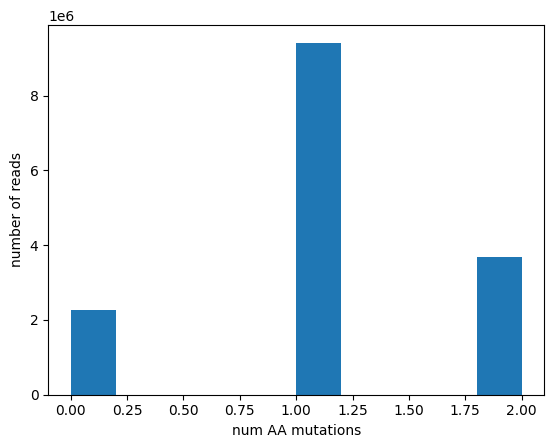

In [39]:
plt.hist(df['numaa_mut'])
plt.xlabel('num AA mutations')
plt.ylabel('number of reads')
plt.show()

In [40]:
df.shape

(15368070, 18)

In [41]:
f = df['numins'] + df['numdel'] < 6
print(f'Removing {sum(~f)} ({sum(~f)/len(f)*100:0.2f}%) reads with num indel >= 6')
df = df.loc[f]

Removing 1020285 (6.64%) reads with num indel >= 6


In [42]:
df.shape

(14347785, 18)

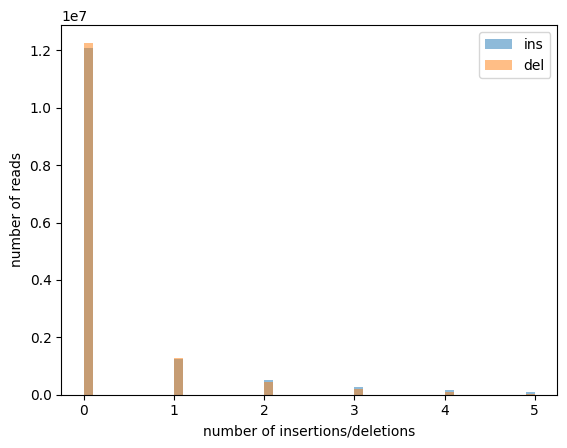

In [43]:
# look at distribution of # of indels across reads
plt.hist(df['numins'], label='ins', bins=50, alpha=0.5)
plt.hist(df['numdel'], label='del', bins=50, alpha=0.5)
plt.legend()
plt.xlabel('number of insertions/deletions')
plt.ylabel('number of reads')
plt.show()

In [44]:
# explore other reasons reads were rejected - this value represents rejected reads to main STING refgene
len(errs['STING'])

5742074

In [45]:
tmp = pd.Series(errs['STING']).value_counts()
tmp['kept'] = df.shape[0]
tmp = pd.DataFrame(tmp)
tmp['frac'] = tmp['count']/sum(tmp['count'])
tmp.sort_values(by='count', ascending=False)

,count,frac
kept,14347785,0.714180
not_aligned,2569119,0.127881
too many aa mutations,1338540,0.066628
no 10x,1128232,0.056159
not enough STING coverage,630981,0.031408
no gene seq,61750,0.003074
investigate flag,13219,0.000658
lowqual,233,0.000012


In [46]:
outdir

'/workdir/satseq/pacbio_data/processed/1_A01'

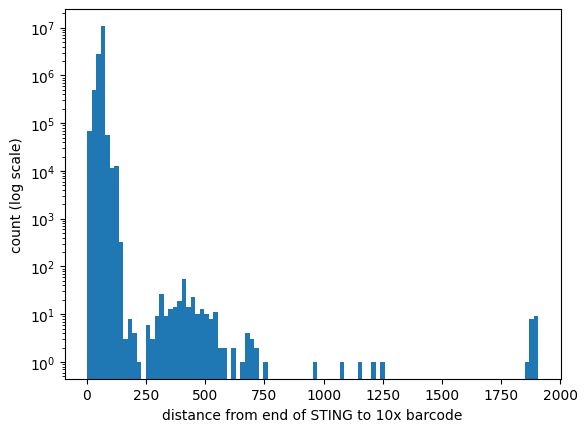

In [47]:
plt.hist(df['10xdist'], bins=100)#, bins=np.arange(0, 200))
plt.xlabel('distance from end of STING to 10x barcode')
plt.yscale('log')
plt.ylabel('count (log scale)')
plt.show()

13707220 0.9553544327573907


Text(0, 0.5, 'count')

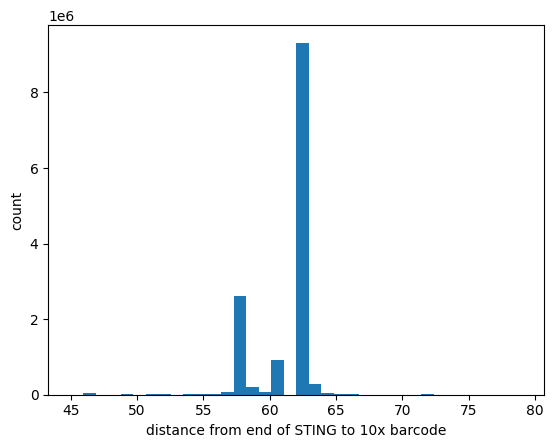

In [48]:
# This is actual distance between 10x barcode and STING. Expected length is 62
# We expect some indels (between gene end and anchorseq), but remove reads where this is way too big or small
f = (df['10xdist'] >=45) & (df['10xdist'] < 80)
print(sum(f), sum(f)/len(f))
plt.hist(df.loc[f,'10xdist'], bins=36)
plt.xlabel('distance from end of STING to 10x barcode')
plt.ylabel('count')

In [49]:
print(f'Removing {sum(~f)} ({sum(~f)/len(f)*100:0.2f}%) barcodes with 10x dist < 45 or > 80')
df = df.loc[f].copy()

Removing 640565 (4.46%) barcodes with 10x dist < 45 or > 80


In [50]:
df['nummut'] = [0 if x=='mSTING_WT' else len(x.split(',')) for x in df['aa_mut']]
df['nummut'].value_counts()

nummut
1    8375355
2    3282343
0    2049522
Name: count, dtype: int64

In [51]:
df['nummut'].value_counts(normalize=True)

nummut
1    0.611018
2    0.239461
0    0.149521
Name: proportion, dtype: float64

In [52]:
sum(df['aa_mut'] == 'mSTING_WT')/df.shape[0]

0.14952134714405985

In [53]:
spikeIns = [x for x in variants.index if not x.endswith('X')]
spikeIns

['mSTING_WT',
 'STOP',
 'V146L',
 'N153S',
 'V154M',
 'S161A',
 'I229A',
 'Y239S',
 'N241A',
 'S365A',
 'RRAA',
 'RRDD',
 'dCTT',
 'dUPR']

In [54]:
spikeIns0 = [x for x in variants.index if not x.endswith('X') and not x[1:-1].isdigit()]
spikeIns0

['mSTING_WT', 'STOP', 'RRAA', 'RRDD', 'dCTT', 'dUPR']

In [55]:
f = df['aa_mut'].isin(spikeIns)
df.loc[f,'aa_mut'].value_counts()

aa_mut
mSTING_WT    2049522
STOP          842453
Y239S           7638
S161A           6819
I229A           6166
RRAA            6163
RRDD            5304
S365A           4801
N241A           3963
V154M           2535
N153S           1095
V146L            999
Name: count, dtype: int64

In [56]:
f = df['aa_mut'].isin(spikeIns0)
df.loc[f,'aa_mut'].value_counts()
print(f'Removing {sum(f)} reads that map to non-positional spike-ins')
df = df.loc[~f]

Removing 2903442 reads that map to non-positional spike-ins


In [57]:
df.shape

(10803778, 19)

In [58]:
# save progress to file so far, in next step we will reduce to unique barcodes
df.to_csv(f'{outdir}/pacbio_mapped_variants.txt.gz', sep='\t', compression='gzip')

In [59]:
# Delete bam file when finished, can be reproduced quickly enough
for ref in ['STING']:
    aligned_file = f'{outdir}/{ref}.bam'
    !rm -f {aligned_file}

## Reduce to unique barcode/aa mutations

In [60]:
os.getcwd()

'/workdir/satseq/satseq_processing'

In [61]:
outdir

'/workdir/satseq/pacbio_data/processed/1_A01'

In [62]:
# If you are starting here, change this to True and load data with this command
if False:
    df = pd.read_csv(f'{outdir}/pacbio_mapped_variants.txt.gz', sep='\t', index_col=0)
df.shape

(10803778, 19)

__Compute entropy of each barcode using all unique AA muts__

In [63]:
# Create a dataframe with each unique mutation - split double-mutations into two entries with count=0.5 each, single mutations get count=1
df2 = df[['bc', 'aa_mut']].copy()
df3 = df.loc[df['numaa_mut'] == 2, ['bc', 'aa_mut']].copy()
df2['count'] = [0.5 if ',' in x else 1.0 for x in df2['aa_mut']]
df3['count'] = 0.5
df2['aa_mut'] = [x.split(',')[0] for x in df2['aa_mut']]
df3['aa_mut'] = [x.split(',')[1] for x in df3['aa_mut']]
dfent = pd.concat([df2,df3], axis=0)
del([df2, df3])
dfent

,bc,aa_mut,count
1,CCTGAGTTGTGGGAGGCGCTGTAAGGGTAGGTATGT,S102T,0.5
4,CCCTGAGTTGTGGAGGCGCTGTAAGGGTAGGTATGT,S102T,0.5
5,CCCTGAGTTGTGGAGGCGCTGTAAGGGTAGGTATGT,S102T,1.0
6,CCCTGAGTTGTGGAGGCGCTGTAAGGGTAGGTATGT,S102T,0.5
7,CCCTGAGTTGTGGAGGCGCTGTAAGGGTAGGTATGT,S102T,1.0
...,...,...,...
15368037,AAGCATCATTCCCGGTCGCTAGGATTGCAGTTAGGA,L116E,0.5
15368058,GCAAGACACTGAGGTCCGCTGTTCGCTATGCCTGAC,Q265_,0.5
15368060,TAATACCGGCTATTAACGCTAGCCTCCACACCGATA,S117N,0.5
15368063,ATTGAACAATCAAATTCGCTAGGATTGCAGTTAGGA,L371P,0.5


In [64]:
bc_mut_df = dfent.groupby(['bc', 'aa_mut']).sum()
bc_mut_df

count
bc                                   aa_mut       
AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT A261T     0.5
                                     N343R     0.5
AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA A48D      0.5
                                     E248V     0.5
AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG A176V     0.5
...                                            ...
TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG R374H     0.5
TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG E338T     1.0
TTTTTTTTTTTTTGCGCGCTTTAGCGTAGAGGGAAC A176E     0.5
                                     A52D      0.5
TTTTTTTTTTTTTTTCCGCTTGCGAAACAGTGAGAG T262M     1.0

[1087914 rows x 1 columns]

In [65]:
bc_mut_df = bc_mut_df.reset_index().set_index('bc').merge(dfent[['bc', 'count']].groupby('bc').sum(), left_index=True, right_index=True,
                                                suffixes=('', '_bc')).reset_index()
bc_mut_df['frac'] = bc_mut_df['count']/bc_mut_df['count_bc']
bc_mut_df['entropy_single'] = -bc_mut_df['frac']*np.log(bc_mut_df['frac'])
bc_df = bc_mut_df[['entropy_single', 'bc']].groupby('bc').sum().merge(dfent[['bc', 'count']].groupby('bc').sum(), 
                                                                      left_index=True, right_index=True).rename(columns={'entropy_single':'entropy'})

bc_df['entropy'] = bc_df['entropy']/np.log(2.0*bc_df['count'])

In [66]:
bc_mut_df

,bc,aa_mut,count,count_bc,frac,entropy_single
0,AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,A261T,0.5,1.0,0.500000,0.346574
1,AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,N343R,0.5,1.0,0.500000,0.346574
2,AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,A48D,0.5,1.0,0.500000,0.346574
3,AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,E248V,0.5,1.0,0.500000,0.346574
4,AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG,A176V,0.5,1.0,0.500000,0.346574
...,...,...,...,...,...,...
1087909,TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG,R374H,0.5,39.0,0.012821,0.055855
1087910,TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG,E338T,1.0,1.0,1.000000,-0.000000
1087911,TTTTTTTTTTTTTGCGCGCTTTAGCGTAGAGGGAAC,A176E,0.5,1.0,0.500000,0.346574
1087912,TTTTTTTTTTTTTGCGCGCTTTAGCGTAGAGGGAAC,A52D,0.5,1.0,0.500000,0.346574


In [67]:
bc_df

,entropy,count
bc,,
AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,1.000000,1.0
AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,1.000000,1.0
AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG,1.000000,1.0
AAAAAAAAAAGACGTGCGCTCTCCACCTTAGACGAC,0.405639,2.0
AAAAAAAAACTGGGATCGCTTCCTATACTGCCCTCG,0.000000,1.0
...,...,...
TTTTTTTTTTGCGTTCTCGCTTAGTAGGCTTTGTCC,1.000000,1.0
TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG,0.188984,39.0
TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG,0.000000,1.0


In [68]:
def get_nearest_variant(origbc):
    varbc=origbc[20:]
    f = varbc == variants['sequence']
    if sum(f) == 1:
        var=variants.loc[f].index[0]
        d=0
    else:
        ds = [editdistance.eval(varbc,x) for x in variants['sequence']]
        tmp = pd.DataFrame({'variant':variants.index, 'd':ds}).sort_values(by='d')
        var =tmp.iloc[0]['variant']
        d = tmp.iloc[0]['d']
    return (origbc, varbc, var, d)

In [69]:
p = multiprocessing.Pool(40)

chunkSize=10000
print('calling get_nearest_variant on all barcodes')
result = p.map_async(get_nearest_variant, bc_df.index, chunkSize)
p.close()
print('done')

calling get_nearest_variant on all barcodes
done


In [70]:
vardist = pd.DataFrame(result.get(), columns=["bc", "var_bc", "closest_variant", "vardist"]).set_index("bc")
bc_df['closest_variant'] = vardist['closest_variant']
bc_df['vardist'] = vardist['vardist']

In [71]:
f = bc_df['closest_variant'].isin(spikeIns0)
print(f'Removing {sum(f)} barcodes whose closest TWIST sequence is a non-positional spike-in')
bc_df = bc_df.loc[~f].copy()
print(bc_df.shape[0])

Removing 4519 barcodes whose closest TWIST sequence is a non-positional spike-in
226776


In [72]:
bc_df['closest_variant_pos'] = [int(x[1:-1]) for x in bc_df['closest_variant']].copy()

In [73]:
bc_df

,entropy,count,closest_variant,vardist,closest_variant_pos
bc,,,,,
AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,1.000000,1.0,N343X,0,343
AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,1.000000,1.0,Y77X,0,77
AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG,1.000000,1.0,S240X,0,240
AAAAAAAAAAGACGTGCGCTCTCCACCTTAGACGAC,0.405639,2.0,I364X,0,364
AAAAAAAAACTGGGATCGCTTCCTATACTGCCCTCG,0.000000,1.0,S365X,0,365
...,...,...,...,...,...
TTTTTTTTTTGCGTTCTCGCTTAGTAGGCTTTGTCC,1.000000,1.0,L100X,2,100
TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG,0.188984,39.0,E338X,0,338
TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG,0.000000,1.0,E338X,2,338


In [74]:
# Doing the inner merge will drop rows from bc_mut_df that correspond to non-positional spike-in barcodes
bc_mut_df = bc_mut_df.merge(bc_df.drop(columns='count'), left_on='bc', right_index=True, how='inner')

In [75]:
bc_mut_df

,bc,aa_mut,count,count_bc,frac,entropy_single,entropy,closest_variant,vardist,closest_variant_pos
0,AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,A261T,0.5,1.0,0.500000,0.346574,1.000000,N343X,0,343
1,AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,N343R,0.5,1.0,0.500000,0.346574,1.000000,N343X,0,343
2,AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,A48D,0.5,1.0,0.500000,0.346574,1.000000,Y77X,0,77
3,AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,E248V,0.5,1.0,0.500000,0.346574,1.000000,Y77X,0,77
4,AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG,A176V,0.5,1.0,0.500000,0.346574,1.000000,S240X,0,240
...,...,...,...,...,...,...,...,...,...,...
1087909,TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG,R374H,0.5,39.0,0.012821,0.055855,0.188984,E338X,0,338
1087910,TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG,E338T,1.0,1.0,1.000000,-0.000000,0.000000,E338X,2,338
1087911,TTTTTTTTTTTTTGCGCGCTTTAGCGTAGAGGGAAC,A176E,0.5,1.0,0.500000,0.346574,1.000000,P225X,0,225
1087912,TTTTTTTTTTTTTGCGCGCTTTAGCGTAGAGGGAAC,A52D,0.5,1.0,0.500000,0.346574,1.000000,P225X,0,225


(array([1.25631e+05, 1.91170e+04, 6.29610e+04, 3.95600e+03, 7.03800e+03,
        5.21500e+03, 2.75900e+03, 9.20000e+01, 6.00000e+00, 1.00000e+00]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

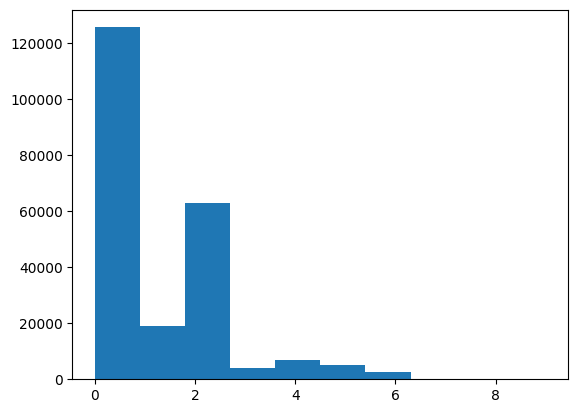

In [76]:
plt.hist(bc_df['vardist'])

In [77]:
bc_mut_df['aa_mut_pos'] = [int(x[1:-1]) for x in bc_mut_df['aa_mut']]

In [78]:
bc_mut_df['match_pos'] = bc_mut_df['closest_variant_pos'] == bc_mut_df['aa_mut_pos']
np.mean(bc_mut_df['match_pos'])

0.13478196240591345

In [79]:
bc_mut_df['match_pos'].value_counts(dropna=False)

match_pos
False    896378
True     139636
Name: count, dtype: int64

In [80]:
# set aa_mut to the most frequently observed per barcode - but prefer mutations in the expected position
# still need to choose entropy cutoff to see whether we will keep this bc/aa_mut pairing
tmp = bc_mut_df.sort_values(by=['bc', 'match_pos', 'frac','aa_mut'], ascending=(True, False, False, True))
tmp = tmp.loc[~tmp['bc'].duplicated()].set_index('bc')
bc_df['aa_mut'] = tmp['aa_mut']
bc_df['aa_mut_frac'] = tmp['count']/tmp['count_bc']
bc_df['match_pos'] = tmp['match_pos'].astype(bool)

In [81]:
bc_df

,entropy,count,closest_variant,vardist,closest_variant_pos,aa_mut,aa_mut_frac,match_pos
bc,,,,,,,,
AAAAAAAAAAAAATGACGCTCCTCTACTTCCGTATT,1.000000,1.0,N343X,0,343,N343R,0.500000,True
AAAAAAAAAAATAACGACCTTGCCTAAAGTCGCGCA,1.000000,1.0,Y77X,0,77,A48D,0.500000,False
AAAAAAAAAACTCCCTCGCTATTCAGACCGTCATAG,1.000000,1.0,S240X,0,240,S240W,0.500000,True
AAAAAAAAAAGACGTGCGCTCTCCACCTTAGACGAC,0.405639,2.0,I364X,0,364,I364T,0.750000,True
AAAAAAAAACTGGGATCGCTTCCTATACTGCCCTCG,0.000000,1.0,S365X,0,365,S365Q,1.000000,True
...,...,...,...,...,...,...,...,...
TTTTTTTTTTGCGTTCTCGCTTAGTAGGCTTTGTCC,1.000000,1.0,L100X,2,100,C71R,0.500000,False
TTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTTGG,0.188984,39.0,E338X,0,338,E338T,0.820513,True
TTTTTTTTTTTTAGCGACGCTTAGCTCGTTCAGTGG,0.000000,1.0,E338X,2,338,E338T,1.000000,True


In [82]:
bc_df['match_pos'].value_counts()

match_pos
True     128104
False     98672
Name: count, dtype: int64

In [83]:
bc_df['match_pos'].value_counts(normalize=True)

match_pos
True     0.564892
False    0.435108
Name: proportion, dtype: float64

In [84]:
# mark which ones have a tie... are they always high entropy?
#  - just change sort parameter, the only sort column that changes is aa_mut. So if only one aa_mut is best it will still be on top
#  - if a different one comes out it is a tie
tmp = bc_mut_df.sort_values(by=['bc', 'match_pos', 'frac', 'aa_mut'], ascending=(True, False, False, False))
tmp = tmp.loc[~tmp['bc'].duplicated()].set_index('bc')
bc_df['aa_mut_tied'] = tmp['aa_mut'] != bc_df['aa_mut']

In [85]:
np.mean(bc_df['match_pos'])

0.5648922284545101

In [86]:
sum(bc_df['aa_mut_tied'])

26546

In [87]:
sum(bc_df['aa_mut_tied'])/bc_df.shape[0]

0.11705824249479663

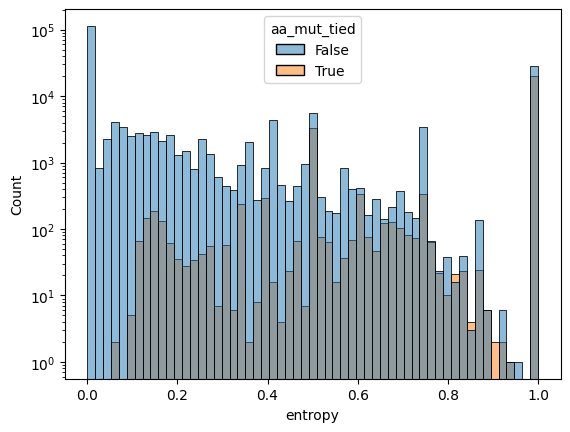

In [88]:
sns.histplot(data=bc_df, x='entropy', hue='aa_mut_tied')
plt.yscale('log')

In [89]:
# If there is a tie and it matches twist position, use it as a positional mutation
# Note: It does not count as a tie if two AA muts are equally frequent but one matches TWIST and the other doesn't. Because
#  ranking considers TWIST match as first criteria. Therefore if match_pos and aa_mut_tied, then both variants must have match_pos
f = (bc_df['aa_mut_tied']) & (bc_df['match_pos'])
print(f'{sum(f)} barcodes have tie for different mutations at expected position, changing to positional mutation')
bc_df.loc[f,'aa_mut'] = [x[:-1]+'X' for x in bc_df.loc[f,'aa_mut']]
bc_df.loc[f,'aa_mut_tied'] = False
bc_df.loc[f]

838 barcodes have tie for different mutations at expected position, changing to positional mutation


,entropy,count,closest_variant,vardist,closest_variant_pos,aa_mut,aa_mut_frac,match_pos,aa_mut_tied
bc,,,,,,,,,
AAAAGGCTGTTCTGGCGCTCACAACGTTGGGAGCTT,0.613147,3.0,L56X,2,56,L56X,0.333333,True,False
AAACTGACATCACACACGCTTGCCTCGGGAATCAGA,0.613147,3.0,L47X,0,47,L47X,0.333333,True,False
AACCCTGTGCACCATCGCCTCAGTGGGAATGTATCA,0.500000,2.0,G250X,0,250,G250X,0.500000,True,False
AAGACTAGACAGTTACGCTTAGTGCCCGCGAACAAG,0.613147,3.0,R177X,2,177,R177X,0.333333,True,False
AAGGGTTTGATTTCAACGCTGTCTCTACTCTGTGAC,0.500000,2.0,P302X,0,302,P302X,0.500000,True,False
...,...,...,...,...,...,...,...,...,...
TTCCACATAGTAAAACGCTACTTAAGGCGCGGTAGA,0.500000,2.0,V21X,2,21,V21X,0.500000,True,False
TTCCGATGTCTGCCATCGCTCACACGTTGGGAGCTT,0.106026,1542.0,L56X,0,56,L56X,0.001297,True,False
TTCTATACGCGGCCCCGCTCTGGAACACATTGCCTC,0.500000,2.0,L184X,2,184,L184X,0.500000,True,False


Deleting 25708 (11.34%) barcodes with tie for best mutation, none matching TWIST


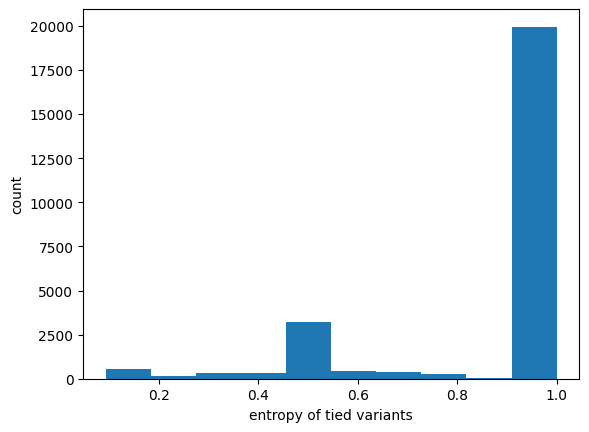

In [90]:
# otherwise if there is a tie, delete
f = bc_df['aa_mut_tied']
print(f'Deleting {sum(f)} ({sum(f)/len(f)*100:0.2f}%) barcodes with tie for best mutation, none matching TWIST')
plt.hist(bc_df.loc[f,'entropy'])
plt.xlabel('entropy of tied variants')
plt.ylabel('count')
bc_df = bc_df.loc[~f]

In [91]:
bc_df.shape

(201068, 9)

Text(0, 0.5, 'count')

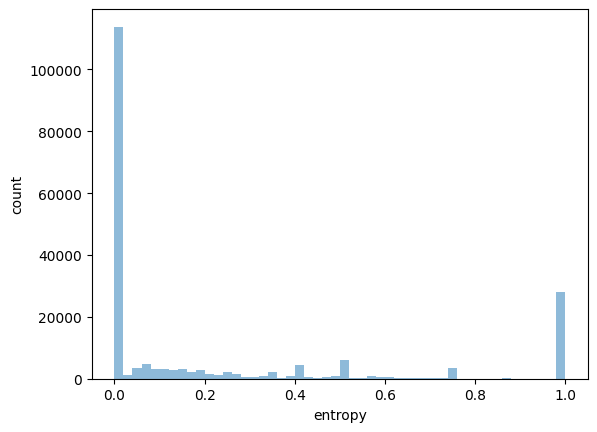

In [92]:
plt.hist(bc_df['entropy'], bins=50, label='all', alpha=0.5)
plt.xlabel('entropy')
plt.ylabel('count')

Text(0, 0.5, 'count')

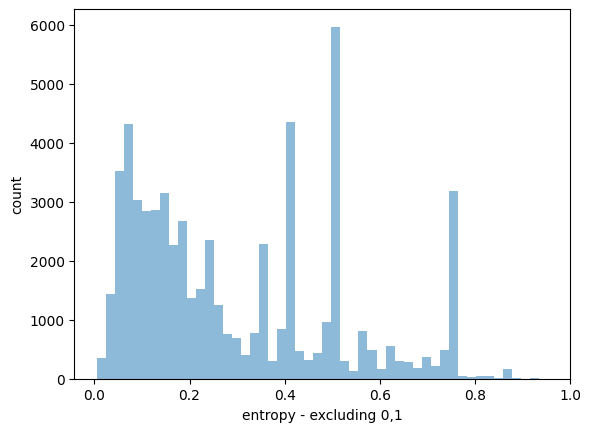

In [93]:
f = (bc_df['entropy'] > 0) & (bc_df['entropy'] < 1)
h = plt.hist(bc_df.loc[f,'entropy'], bins=50, label='all', alpha=0.5)
plt.xlabel('entropy - excluding 0,1')
plt.ylabel('count')

Text(0, 0.5, 'count')

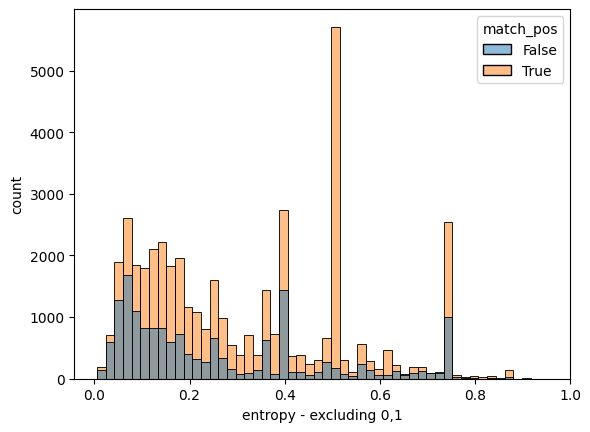

In [94]:
f = (bc_df['entropy'] > 0) & (bc_df['entropy'] < 1)
sns.histplot(data=bc_df.loc[f], x='entropy', hue='match_pos')
plt.xlabel('entropy - excluding 0,1')
plt.ylabel('count')

In [95]:
bc_df['match_pos'].value_counts(dropna=False)

match_pos
True     128104
False     72964
Name: count, dtype: int64

In [96]:
bc_df['match_pos'].value_counts(dropna=False, normalize=True)

match_pos
True     0.637118
False    0.362882
Name: proportion, dtype: float64

In [97]:
f  = (bc_df['entropy'] > 0.5) & (~(bc_df['match_pos'].astype(bool)))
print(f'Deleting {sum(f)} ({sum(f)/len(f)*100:0.2f}%) barcodes with entropy > 0.5 and and not matching TWIST')
bc_df = bc_df.loc[~f].copy()

Deleting 2302 (1.14%) barcodes with entropy > 0.5 and and not matching TWIST


In [98]:
bc_df['score'] = (1.0-bc_df['entropy'])*np.log10(bc_df['aa_mut_frac']*bc_df['count'])

Text(0, 0.5, '# of barcodes')

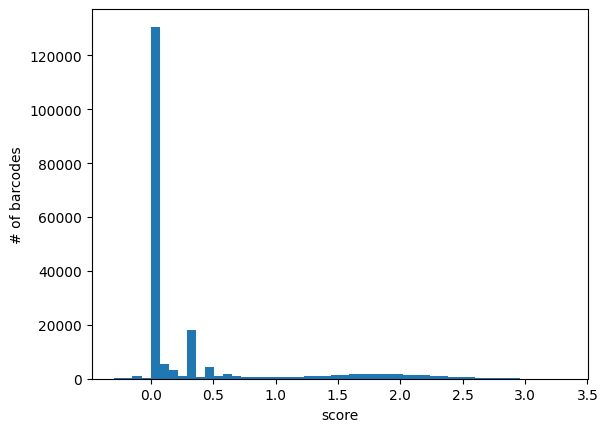

In [99]:
plt.hist(bc_df['score'], bins=50)
plt.xlabel('score')
plt.ylabel('# of barcodes')

In [100]:
bc_df.columns

Index(['entropy', 'count', 'closest_variant', 'vardist', 'closest_variant_pos',
       'aa_mut', 'aa_mut_frac', 'match_pos', 'aa_mut_tied', 'score'],
      dtype='object')

In [101]:
bc_df['closest_variant_pos'] = [int(x[1:-1]) for x in bc_df['closest_variant']]

Text(0.5, 1.0, '4T1 pacbio')

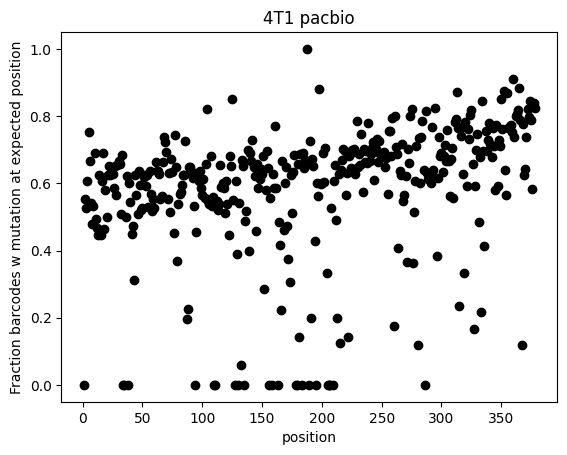

In [102]:
tmp = bc_df[['closest_variant_pos', 'match_pos']].groupby('closest_variant_pos').mean()
tmp.to_csv(f'{outdir}/recomb_plot_data.txt', sep='\t')
plt.scatter(tmp.index, tmp['match_pos'], color='black')
plt.ylim(-0.05, 1.05)
plt.xlabel('position')
plt.ylabel('Fraction barcodes w mutation at expected position')
plt.title(sample_name)

In [103]:
bcmap = bc_df[['aa_mut', 'score', 'closest_variant', 'vardist', 'match_pos', 'count', 'closest_variant_pos']].copy()

__Write barcode map, this is used in 10x mapping__

In [104]:
bcmap.to_csv(f'{outdir}/bcmap.txt.gz', sep='\t')
print(f'Wrote {outdir}/bcmap.txt.gz')

Wrote /workdir/satseq/pacbio_data/processed/1_A01/bcmap.txt.gz


In [105]:
outdir

'/workdir/satseq/pacbio_data/processed/1_A01'

### Plot of position vs AA mutation coverage

In [106]:
# get matrix wt_matrix indicating WT alleles in STING
tmp = variants[['pos','wt_aa']].rename(columns={'wt_aa':'newaa'}).copy()
tmp = tmp.loc[tmp['pos'] > 0]
tmp = tmp.reset_index(drop=True)
tmp = tmp[~tmp.duplicated()].sort_values(by='pos').set_index('pos', drop=True)
tmp['val'] = 1.0
wt_mat = tmp.reset_index().pivot(columns='newaa', index='pos')
wt_mat[pd.isna(wt_mat)] = 0.0
wt_mat.columns=[x[1] for x in wt_mat.columns]

In [107]:
wt_mat

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
374,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
376,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [108]:
np.sum(wt_mat==1, axis=1).sort_values()

pos
345    1
346    1
347    1
348    1
349    1
      ..
375    1
376    1
377    1
378    1
1      1
Length: 378, dtype: int64

In [109]:
# Same as plot_coverage but with new colors requested by matt:
# (Red = Not detected, Black = Native, Green = Detected)
# Only implemeneted for the observed_per_pos plot (binary yes/no observed)

# If show_counts is True, then use gradient colormap to show number of reads, WT will be pink
# If show_counts is False, blue=count > 0 , red=count=0, black=WT
def plot_coverage(bcmap, bcmap_name, outdir, show_counts=True, show=True):
    f =  (~(bcmap['aa_mut'].isin(['STOP', 'RRAA', 'dUPR', 'RRDD', 'dCTT', 'mSTING_WT'])))
    bcmap['pos'] = [int(x[1:-1]) for x in bcmap['aa_mut']]
    f = (f) & (bcmap['pos'] <= 378) 
    bcmap['newaa'] = ''
    bcmap.loc[f,'newaa'] = [x[-1] for x in bcmap.loc[f,'aa_mut']]
    f = (f) & (bcmap['newaa'] != '_')
    colorder = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q',
       'R', 'S', 'T', 'V', 'W', 'Y']#, '_']
    positions = list(np.arange(1,379))
    tmp = bcmap.loc[bcmap['newaa'] != '', ['pos', 'newaa']].copy()
    tmp['pos'] = pd.Categorical(tmp['pos'], categories=positions)
    tmp['newaa'] = pd.Categorical(tmp['newaa'], categories=colorder)
    tmp = tmp.value_counts().reset_index()
    bc_count_mat = tmp.pivot_table(columns='newaa', index='pos', values='count', observed=False, dropna=False).loc[positions, colorder]
    f = pd.isna(bc_count_mat)
    bc_count_mat[f]=0
    if np.sum(np.sum(bc_count_mat*wt_mat, axis=1))!=0:
        print('error')

    

    _, ax = plt.subplots(figsize=(6, 20))
    if show_counts:
        label='counts'
        wt_color='rosybrown'
        sns.heatmap(bc_count_mat > 0, ax=ax, cmap='Blues',cbar=True)
    else:
        cmap = ListedColormap(["red", "skyblue"])
        label='observed'
        wt_color='black'
        sns.heatmap(bc_count_mat > 0, ax=ax, cmap=cmap,cbar=False, vmin=0.0, vmax=1)
    numfound = np.sum(np.sum(bc_count_mat > 0, axis=1))
    fracfound = numfound/np.sum(np.sum(wt_mat!=1, axis=1))
    print(f'{bcmap_name}\t{numfound}\t{fracfound*100:0.2f}%')
    for i in wt_mat.index:
        position = np.where(wt_mat[colorder].loc[i] != 0)[0][0]
        ax.add_patch(Rectangle((position, i-1), 1, 1, fill=True, edgecolor=wt_color, lw=0, facecolor=wt_color))

    plt.title(f'{bcmap_name} AA muts {label}')
    
    plt.savefig(f'{outdir}/{label}_per_pos_aa_{bcmap_name}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'{outdir}/{label}_per_pos_aa_{bcmap_name}.svg', bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.clf()

4T1 pacbio	5799	80.74%


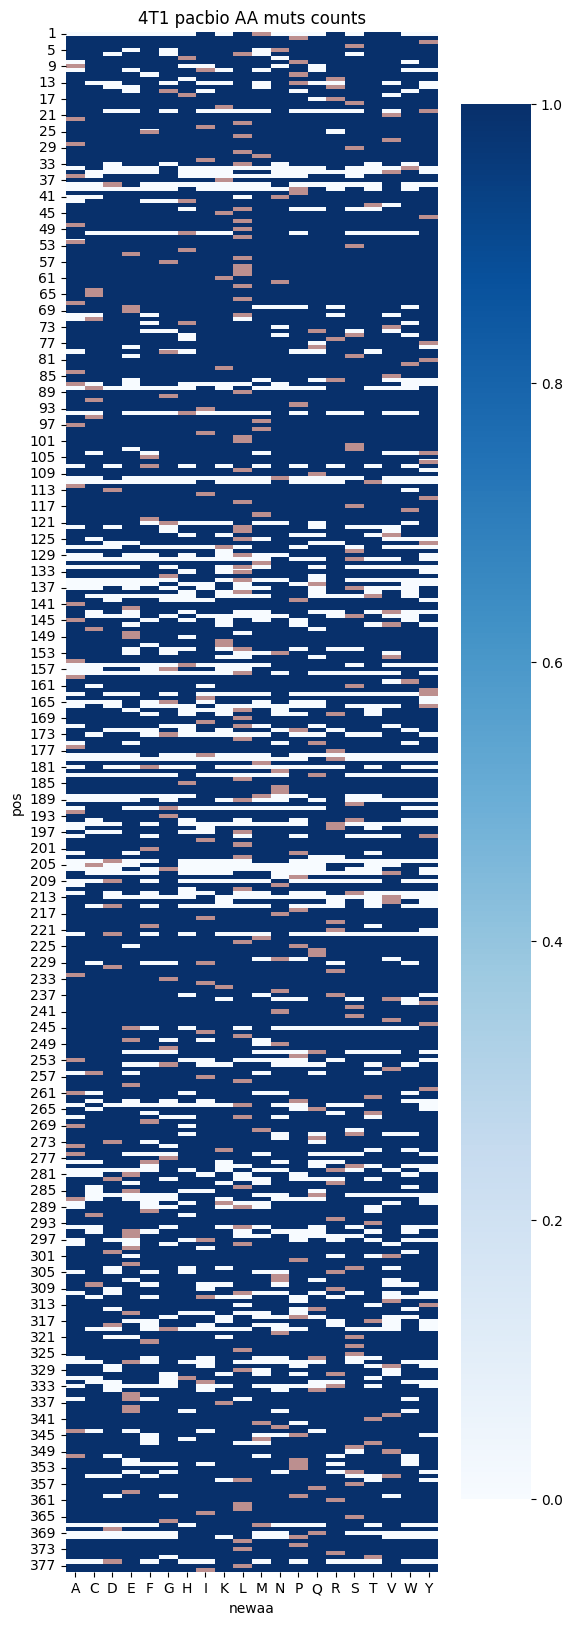

In [110]:
plot_coverage(bcmap, sample_name, outdir)

4T1 pacbio	5799	80.74%


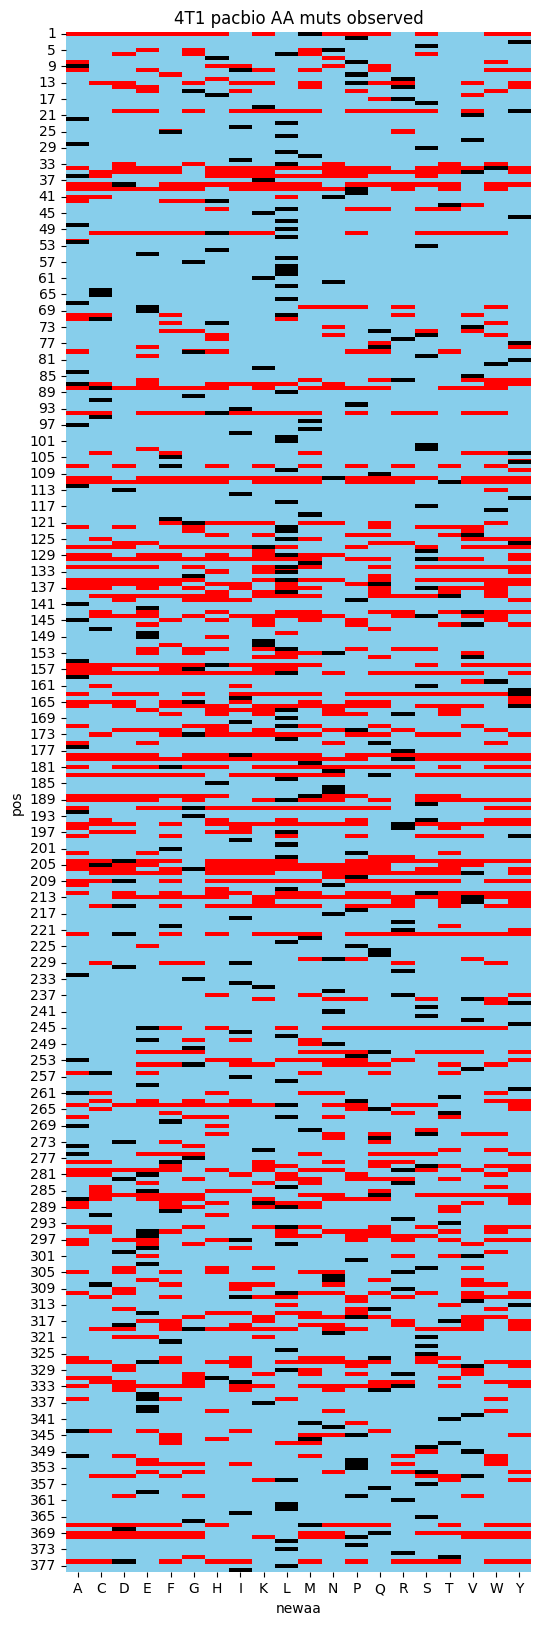

In [111]:
# blue = observed
# red = not observed
# black = WT
plot_coverage(bcmap, sample_name, outdir, show_counts=False)